# 1 Hafta, 1 Veri Hikâyesi | #01
## Türkiye’de konut fiyatlarının nominal ve reel analizi

**Araştırma sorusu:** Konut fiyatlarının TL cinsinden artması, enflasyondan arındırılmış değerlerinin de arttığı anlamına geliyor mu?

**Dönem:** Ocak 2020 – Ekim 2026 (veri setlerinde mevcutsa). **Kaynak:** TCMB Konut Fiyat Endeksi (KFE), TÜİK Tüketici Fiyat Endeksi (TÜFE).

> Bu notebook, kullanıcının özgün `VeriBil1.ipynb` çalışmasındaki veri hazırlama ve analiz yaklaşımının düzenlenmiş sürümüdür. Ham Excel dosyaları bu sohbet içinde bulunmadığından sonuçlar burada yeniden çalıştırılarak doğrulanmamıştır.

### 1. Kurulum ve dosyalar

`data/` klasörüne iki Excel dosyasını koyun:
- `data/konut_fiyat_endeksi.xlsx` — TCMB, Türkiye geneli KFE **Düzey** serisi
- `data/tufe.xlsx` — TÜİK, genel TÜFE **Endeks** serisi

İndirilen tabloların kolon başlıkları değişebilir. Kod, özgün notebook'ta görülen `TP_KFE_TR(Duzey)`, `Endeks  ` ve `Endeks-Değişim  ` isimlerine göre hazırlanmıştır; farklı dosyalarda kontrol edin.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("data")
kfe_raw = pd.read_excel(DATA / "konut_fiyat_endeksi.xlsx")
tufe_raw = pd.read_excel(DATA / "tufe.xlsx")

print("KFE sütunları:", kfe_raw.columns.tolist())
print("TÜFE sütunları:", tufe_raw.columns.tolist())

KFE sütunları: ['Tarih', 'TP_KFE_TR(Duzey)', 'TP_KFE_TR-1(Y.Degisim)', 'TP_KFE_TR-3(Aylık Degisim)']
TÜFE sütunları: ['Endeks-Değişim  ', 'Endeks  ', 'Bir önceki aya göre değişim oranı (%)  ', 'Bir önceki yılın Aralık ayına göre değişim (%)  ', 'Bir önceki yılın aynı ayına göre (yıllık) değişim oranı (%)  ', 'Oniki aylık ortalamalara göre değişim (%)  ']


### 2. Temizleme ve aylık tarih eşleştirmesi

Sütun adlarının çevresindeki boşlukları temizliyoruz. TÜFE dosyasındaki `Zaman` gibi açıklama satırlarını geçerli tarih dönüşümüyle ayıklıyoruz. Her iki veri setini ay düzeyinde eşleştiriyoruz. Endeks düzeyleri sayısal olmalı; dönüştürülemeyen kayıtları açıkça kontrol ediyoruz.

In [5]:
kfe = kfe_raw.copy()
tufe = tufe_raw.copy()
kfe.columns = kfe.columns.astype(str).str.strip()
tufe.columns = tufe.columns.astype(str).str.strip()

kfe = kfe.rename(columns={"TP_KFE_TR(Duzey)": "KFE"})
tufe = tufe.rename(columns={"Endeks-Değişim": "Tarih", "Endeks": "TUFE"})

for name, table, needed in [("KFE", kfe, ["Tarih", "KFE"]), ("TÜFE", tufe, ["Tarih", "TUFE"])]:
    missing = [c for c in needed if c not in table.columns]
    if missing:
        raise ValueError(f"{name} dosyasında beklenen sütun bulunamadı: {missing}; mevcut: {table.columns.tolist()}")

def clean_monthly(table, value_col):
    result = table[["Tarih", value_col]].copy()
    result["Tarih"] = pd.to_datetime(
        result["Tarih"].astype(str).str.strip(), format="%Y-%m", errors="coerce"
    ).dt.to_period("M")
    result[value_col] = pd.to_numeric(result[value_col], errors="coerce")
    result = result.dropna(subset=["Tarih"])
    bad = result[value_col].isna().sum()
    if bad:
        raise ValueError(f"{value_col} sütununda {bad} sayısal olmayan endeks değeri var; Excel biçimini kontrol edin.")
    if (result[value_col] <= 0).any():
        raise ValueError(f"{value_col} endeksinde sıfır veya negatif değer var.")
    if result["Tarih"].duplicated().any():
        raise ValueError(f"{value_col} serisinde tekrarlanan aylar var.")
    return result.sort_values("Tarih").reset_index(drop=True)

kfe = clean_monthly(kfe, "KFE")
tufe = clean_monthly(tufe, "TUFE")
print("KFE:", kfe["Tarih"].min(), kfe["Tarih"].max(), len(kfe))
print("TÜFE:", tufe["Tarih"].min(), tufe["Tarih"].max(), len(tufe))

KFE: 2012-01 2026-10 178
TÜFE: 2005-01 2026-10 262


### 3. Birleştirme ve veri kalite kontrolü

`inner join`, iki veri setinin ortak aylarını tutar. Ocak 2020–Ekim 2026 aralığını inceliyoruz. **82 ay** beklenir. Eksik ay varsa yıllık karşılaştırmalar yanlış olabileceği için kod durur.

In [7]:
df = pd.merge(kfe, tufe, on="Tarih", how="inner")
df = df[(df["Tarih"] >= pd.Period("2020-01", freq="M")) &
        (df["Tarih"] <= pd.Period("2026-10", freq="M"))].copy()
df = df.sort_values("Tarih").reset_index(drop=True)
expected = pd.period_range("2020-01", "2026-10", freq="M")
missing_months = expected.difference(pd.PeriodIndex(df["Tarih"], freq="M"))
print("Gözlem sayısı:", len(df))
print("Eksik aylar:", list(missing_months))
print("Eksik değerler:\n", df.isna().sum())
print("Tekrarlanan ay:", df["Tarih"].duplicated().sum())
if len(missing_months) or len(df) != len(expected):
    raise ValueError("Analiz dönemi eksiksiz değil; kaynak verileri kontrol edin.")
df.head()

Gözlem sayısı: 82
Eksik aylar: []
Eksik değerler:
 Tarih    0
KFE      0
TUFE     0
dtype: int64
Tekrarlanan ay: 0


,Tarih,KFE,TUFE
0,2020-01,12.61,14.025066
1,2020-02,12.89,14.074387
2,2020-03,13.13,14.154809
3,2020-04,13.15,14.275755
4,2020-05,13.40,14.470212


### 4. Nominal ve reel endeks hesaplama

Her iki endeksi **Ocak 2020 = 100** olacak şekilde yeniden ölçekliyoruz.

- Nominal endeks = KFE / başlangıç KFE × 100
- Normalize TÜFE = TÜFE / başlangıç TÜFE × 100
- Reel endeks = Nominal endeks / Normalize TÜFE × 100

Bu hesap TÜFE ile deflate edilmiş KFE'yi gösterir; bireysel konut yatırımının toplam getirisini göstermez.

In [9]:
df["Nominal"] = df["KFE"] / df["KFE"].iloc[0] * 100
df["TUFE_Normalize"] = df["TUFE"] / df["TUFE"].iloc[0] * 100
df["Reel"] = df["Nominal"] / df["TUFE_Normalize"] * 100
df["Nominal_Yillik"] = df["KFE"].pct_change(12) * 100
df["Reel_Yillik"] = df["Reel"].pct_change(12) * 100
df["Tarih_Grafik"] = df["Tarih"].dt.to_timestamp()
df[["Tarih", "Nominal", "Reel", "Nominal_Yillik", "Reel_Yillik"]].tail()

,Tarih,Nominal,Reel,Nominal_Yillik,Reel_Yillik
77,2026-06,1834.575734,197.938655,24.403097,-5.833014
78,2026-07,1860.031721,197.166258,24.906806,-5.197023
79,2026-08,1875.495638,195.205567,22.895448,-6.548604
80,2026-09,1896.748612,193.849920,22.242666,-5.772572
81,2026-10,1910.626487,190.357765,21.149495,-6.642011


### 5. Bulguların hesaplanması

Başlangıçtan son aya değişim, reel zirve tarihi, zirveden gerileme ve son 12 ayın değişimini hesaplıyoruz. Sonuçları önceden sabit sayılarla yazmak yerine doğrudan veriden üretiyoruz.

In [11]:
ilk, son = df.iloc[0], df.iloc[-1]
zirve = df.loc[df["Reel"].idxmax()]
nominal_degisim = (son["Nominal"] / ilk["Nominal"] - 1) * 100
reel_degisim = (son["Reel"] / ilk["Reel"] - 1) * 100
zirveden_degisim = (son["Reel"] / zirve["Reel"] - 1) * 100
son_12_nominal = son["Nominal_Yillik"]
son_12_reel = son["Reel_Yillik"]

print(f"Dönem: {ilk['Tarih']} – {son['Tarih']}")
print(f"Nominal değişim: %{nominal_degisim:.2f}")
print(f"Reel değişim: %{reel_degisim:.2f}")
print(f"Reel zirve: {zirve['Tarih']} (endeks {zirve['Reel']:.2f})")
print(f"Zirveden değişim: %{zirveden_degisim:.2f}")
print(f"Son 12 ay nominal: %{son_12_nominal:.2f}")
print(f"Son 12 ay reel: %{son_12_reel:.2f}")

Dönem: 2020-01 – 2026-10
Nominal değişim: %1810.63
Reel değişim: %90.36
Reel zirve: 2023-06 (endeks 250.58)
Zirveden değişim: %-24.03
Son 12 ay nominal: %21.15
Son 12 ay reel: %-6.64


### 6. Görselleştirme

İlk grafik iki endeksi karşılaştırır. İkinci grafik reel endekse odaklanır ve zirveyi işaretler. Görseller `visuals/` klasörüne kaydedilir.

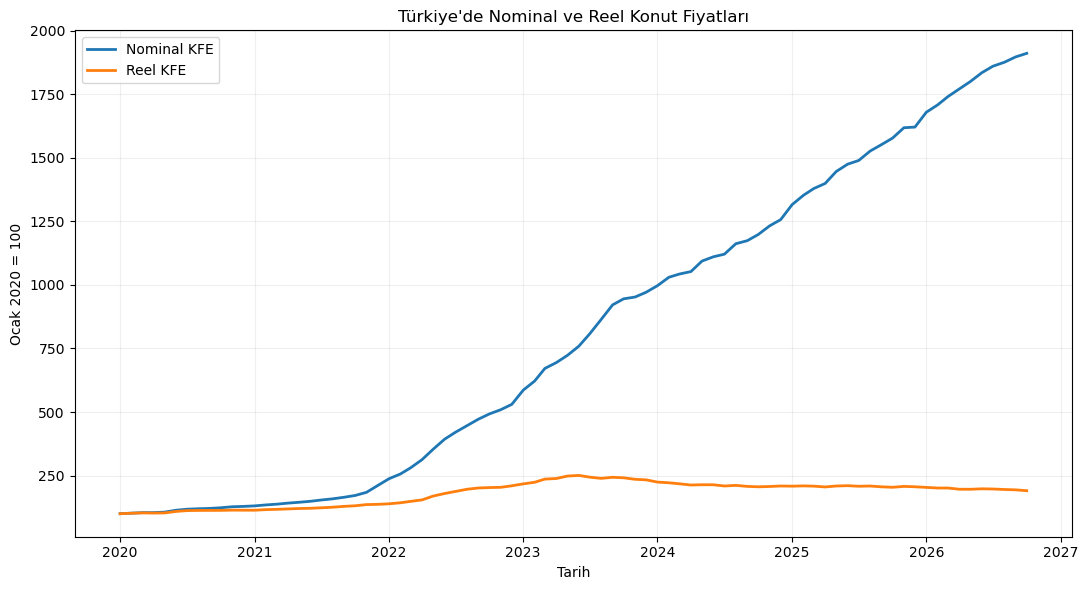

In [13]:
VISUALS = Path("visuals")
VISUALS.mkdir(exist_ok=True)
fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(df["Tarih_Grafik"], df["Nominal"], label="Nominal KFE", lw=2)
ax.plot(df["Tarih_Grafik"], df["Reel"], label="Reel KFE", lw=2)
ax.set(title="Türkiye'de Nominal ve Reel Konut Fiyatları", ylabel="Ocak 2020 = 100", xlabel="Tarih")
ax.grid(alpha=.2); ax.legend(); fig.tight_layout()
fig.savefig(VISUALS / "nominal_reel_karsilastirma.png", dpi=200)
plt.show()

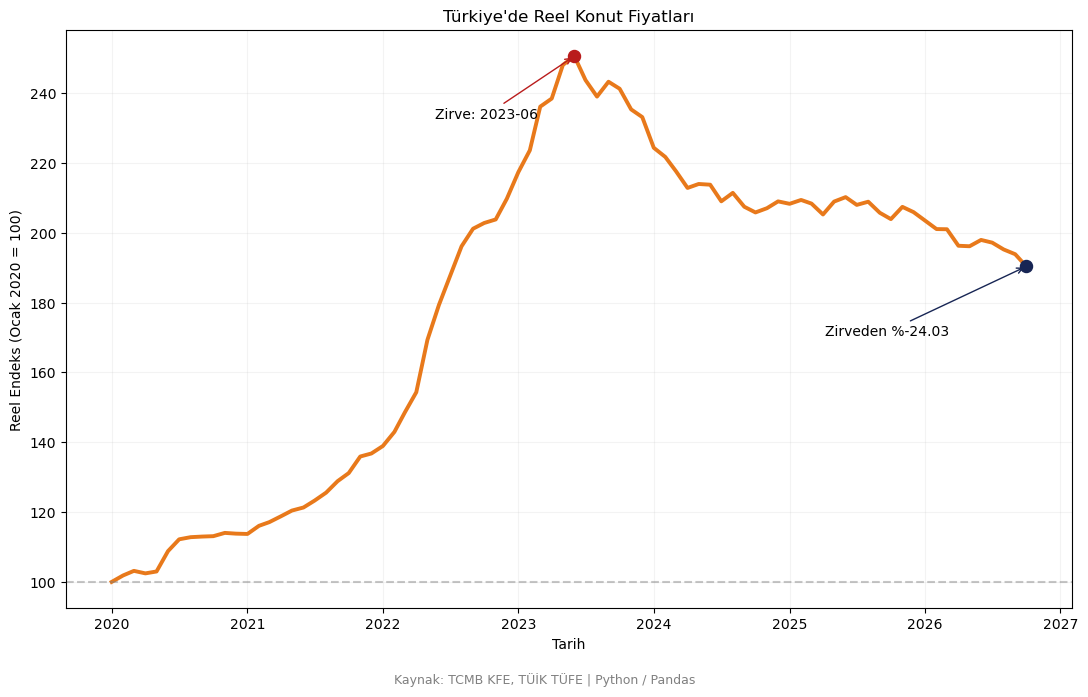

In [14]:
fig, ax = plt.subplots(figsize=(11, 7))
ax.plot(df["Tarih_Grafik"], df["Reel"], color="#e8791b", lw=2.8)
ax.axhline(100, color="gray", ls="--", alpha=.45)
peak_date = zirve["Tarih"].to_timestamp()
last_date = son["Tarih"].to_timestamp()
ax.scatter([peak_date], [zirve["Reel"]], color="#b91c1c", s=75, zorder=5)
ax.scatter([last_date], [son["Reel"]], color="#172554", s=75, zorder=5)
ax.annotate(f"Zirve: {zirve['Tarih']}", (peak_date, zirve["Reel"]),
            xytext=(-100,-45), textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color="#b91c1c"))
ax.annotate(f"Zirveden %{zirveden_degisim:.2f}", (last_date, son["Reel"]),
            xytext=(-145,-50), textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color="#172554"))
ax.set(title="Türkiye'de Reel Konut Fiyatları", ylabel="Reel Endeks (Ocak 2020 = 100)", xlabel="Tarih")
ax.grid(alpha=.15)
fig.text(.5,.015,"Kaynak: TCMB KFE, TÜİK TÜFE | Python / Pandas",ha="center",fontsize=9,color="gray")
fig.tight_layout(rect=[0,.04,1,1])
fig.savefig(VISUALS / "reel_konut_fiyatlari.png", dpi=300, bbox_inches="tight")
plt.show()

### 7. Bulgular, yorum ve sınırlılıklar

**Özgün çalışmanın raporladığı sonuçlar** (ham Excel dosyaları sağlandığında yukarıdaki kodla yeniden doğrulanmalıdır):

- Ocak 2020–Ekim 2026 nominal KFE değişimi: **+%1.810,63**
- Aynı dönemde reel KFE değişimi: **+%90,36**
- Reel zirve: **Haziran 2023**
- Zirveden Ekim 2026'ya reel değişim: **−%24,03**
- Son 12 ay nominal: **+%21,15**, reel: **−%6,64**

**Yorum:** Başlangıç dönemine kıyasla reel endeks artmış olmakla birlikte, 2023 zirvesinden sonra gerilemiştir. Nominal artış ile reel artış aynı değildir.

**Sınırlılıklar:** Türkiye geneli endeksleri bölgesel farkları, kira gelirini, vergi ve işlem maliyetlerini kapsamaz. Resmî serilerin baz yılı/metodoloji değişiklikleri, uzun dönem kıyaslaması öncesinde kaynaklardan ayrıca kontrol edilmelidir.

**Tekrar üretilebilirlik:** Ham veri dosyalarını `data/` klasörüne koyup notebook'u baştan sona çalıştırın. Kaynak verileri paylaşma koşullarını kontrol edin.